# Census comparison areas and indicators

**Final file:** `datasets/census/census_comparison_areas_2010_2022.gpkg`. The `social` layer has one merged 2022 geometry per `common_id`; `overview` has municipality display summaries. `field_dictionary` maps each original variable code to its single clear English column, unit and meaning; `export_metadata` records provenance.

**Input:** Preserved IBGE tract geometry, 2010/2022 census tables and checked correspondence inputs at the paths in [`datasets/project.toml`](../project.toml).

**Process, in order:**
1. [Match tracts](../shared/brazil_project/harmonisation/census.py) by largest positive-area overlap in both directions and keep complete connected comparison groups.
2. [Calculate indicators](../shared/brazil_project/indicators/temporal.py) for each year using their original numerators, denominators and missing-value rules.
3. [Build map fields and geometry](../shared/scripts/build_web_map.py): merge 2022 tract pieces by `common_id` and make a separate municipality overview.
4. [Export clear English fields](../shared/scripts/export_social_gpkg.py), retain the original-code dictionary, verify the output and copy it to `census_comparison_areas_2010_2022.gpkg`. [This folder's processing code](processing.py) connects these steps.

**Source note:** The provider is [IBGE](https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/2971-np-malhas-de-setores-censitarios-divisoes-intramunicipais/26565-malhas-de-setores-censitarios-divisoes-intramunicipais.html). The saved tables came from a [censobr v0.5.0](https://github.com/ipea/censobr/releases/tag/v0.5.0) cache; the original project supplied the tract GeoPackage. Its [archived R acquisition script](https://github.com/fab1s/brazil-project/blob/archive/full-project-2026-10-27/code/scripts/r/acquire_census.R) records the retrieval method. The notebook processes the preserved files; it does not download them.

In [1]:
DATASET = "census"
from pathlib import Path
import os, sys, sqlite3
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "datasets/project.toml").is_file())
sys.path[:0] = [str(PROJECT / "datasets" / "shared"), str(PROJECT / "datasets"), str(PROJECT / "datasets" / DATASET)]
from processing import build, inspect_final
REBUILD = os.environ.get("BRAZIL_NOTEBOOK_REBUILD", "1") == "1"
print("Project:", PROJECT.name)
print("Mode:", "build from local inputs" if REBUILD else "preview existing verified local output")

Project: brazil-project
Mode: preview existing verified local output


## 1. Match tracts and calculate indicators

The matcher chooses each tract's largest **positive-area** overlap in both directions, connects the resulting pairs, and retains whole connected groups. Point or line contact alone is not a match. The saved national baseline is checked against this rule; unchanged groups keep their IDs, while changed groups receive stable member-derived IDs. Missing tracts stay in an unmatched inventory rather than being assigned to a neighbour. The 2022 pieces are dissolved by `common_id` for analytical geometry; original pieces remain in the intermediate bundle.

Annual values are calculated from each year's original tables and joined through the versioned lookup. Each measure retains its own numerator, denominator and missing-value rule; zero denominators are unavailable rather than zero. Income uses household-head weights and the recorded 2010-to-2022 inflation adjustment. Density uses equal-area EPSG:6933 for the denominator, while the delivered geometry stays EPSG:5880. A national run can take time.

In [2]:
from processing import calculate_indicators, export_geopackage
if REBUILD:
    calculate_indicators(PROJECT)
else:
    print("Preview: existing producer artifacts; harmonisation and indicators were not rerun.")

Preview: existing producer artifacts; harmonisation and indicators were not rerun.


## 2. Export the research GeoPackage

The exporter rebuilds the full-resolution common areas and a simplified **display-only** municipality overview. It checks the active bundle and every saved indicator fingerprint before writing English column names. Two original fields share one final column only when their units, values and missingness are exactly equal; all original-to-English mappings remain in `field_dictionary`. Shares are fractions, share changes are percentage points, and density/income changes are relative percentages.

In [3]:
result = export_geopackage(PROJECT) if REBUILD else inspect_final(PROJECT, preview=True)
display(pd.DataFrame([{
    "common areas": result["features"],
    "municipality overview": result["overview_rows"],
    "original→English mappings": result["field_dictionary_rows"],
    "CRS": f"EPSG:{result['epsg']}"}]))
print("Local GeoPackage:", Path(result["file"]).relative_to(PROJECT))
print("SHA-256:", result["sha256"])

,common areas,municipality overview,original→English mappings,CRS
0,287178,5570,187,EPSG:5880


Local GeoPackage: datasets/census/census_comparison_areas_2010_2022.gpkg
SHA-256: 7547b9773fe36a0d3407105a77bae8c861791cf85a2ce263828200c5d7e251b9


## 3. Check the comparison-area types

Counts below describe **common areas**, not residents. A split or merge says how tract memberships relate across the two censuses; it does not by itself measure population change. One-to-one means one tract in each year; split and merge describe changes in tract membership; complex groups involve several tracts in both years.

,type,Common areas
0,One-to-one,188105
1,Split,79455
2,Complex,15189
3,Merge,4429


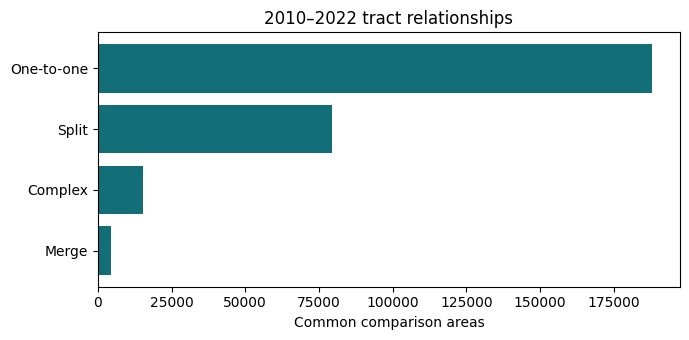

In [4]:
with sqlite3.connect(f"file:{result['file']}?mode=ro", uri=True) as db:
    relation = pd.read_sql_query('SELECT tract_relationship AS relationship, COUNT(*) AS common_areas FROM social GROUP BY tract_relationship ORDER BY common_areas DESC', db)
labels = {"1:1": "One-to-one", "2010_to_2022_split": "Split", "2010_to_2022_merge": "Merge", "many_to_many": "Complex"}
relation["type"] = relation.relationship.map(labels).fillna(relation.relationship)
display(relation[["type", "common_areas"]].rename(columns={"common_areas": "Common areas"}))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(relation.type.iloc[::-1], relation.common_areas.iloc[::-1], color="#126f78")
ax.set_xlabel("Common comparison areas")
ax.set_title("2010–2022 tract relationships")
fig.tight_layout()
display(fig)
plt.close(fig)

**Interpretation and limits:** The shape is the complete 2022 group footprint, not a fixed intersection of both years. The researcher accepts the assumption that boundary changes do not materially alter inhabited population; that has not been established for every group. Municipality overview rows may include complete groups crossing municipal boundaries. The GeoPackage stays local because of its size. The earlier full policy and validation record are preserved on the [archive branch](https://github.com/fab1s/brazil-project/tree/archive/full-project-2026-10-27/docs).

## Verification and recovery

The 2026-10-27 national rebuild produced **287,178** `social` areas, **5,570** overview rows and **187** field mappings. Every row in these three tables, including geometry blobs, matched an earlier reviewed external comparison copy; only file-level generation metadata changed. The processing code checks unique `common_id`, CRS, GeoPackage integrity, input fingerprints and each source-to-English value mapping before publishing. If an input or code fingerprint changes during export, it stops before replacing `census_comparison_areas_2010_2022.gpkg`; restore the configured inputs and rerun this notebook. National correspondence recomputation against all tract geometries is a separate research validation task, not claimed by this check.

**Local handoff:** `census_comparison_areas_2010_2022.gpkg` is EPSG:5880 and had SHA-256 `7547b9773fe36a0d3407105a77bae8c861791cf85a2ce263828200c5d7e251b9` on 2026-10-27. Share this file separately from GitHub and compare its checksum after transfer. A new export can change whole-file metadata while preserving the research rows.